# Compile for hardware constraints

An input program names qubits and gates. Hardware offers physical sites,
connections, and a native gate set. What changes when the program's interactions
do not fit those connections?

This tutorial runs independently with the
[tutorial setup](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/index.html#run-the-notebooks). The targets below are small models
for compilation. Execution uses the bundled DDSIM simulator and requires no
hardware account or external device.

**Notebook 02 · Next 20 minutes.** Predict the output, compile for the two
target models, and compare their native circuits. Check connectivity and logical
results, then stop at the checkpoint below. Device submission is covered in
Notebook 03 after the QDMI introduction.

In [1]:
from IPython.display import Code, display
from matplotlib import pyplot as plt
from qiskit.visualization import plot_distribution

from mqt.core.mlir import (
    CompilerTarget,
    OutputFormat,
    QCProgram,
    compile_program,
    sample,
    submit_program,
)
from mqt.core.qdmi import open_device

## Predict the logical result

The first two controlled-X gates prepare a three-qubit GHZ state. The final
controlled-X flips the third qubit when the first is 1. Starting from
$|000\rangle$, the result is $(|000\rangle + |011\rangle)/\sqrt{2}$ in basis
order $|q_2q_1q_0\rangle$.

The three gates connect **every pair of program qubits**. No assignment of three
qubits to a three-site line can make all three pairs adjacent.

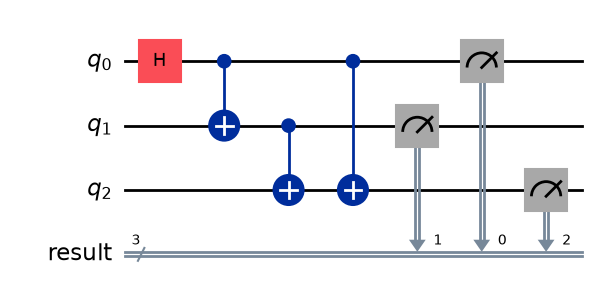

In [2]:
source = """OPENQASM 3.0;
include "stdgates.inc";
qubit[3] q;
bit[3] result;
h q[0];
cx q[0], q[1];
cx q[1], q[2];
cx q[0], q[2];
result = measure q;
"""
shots = 4096
seed = 17

logical = QCProgram.from_openqasm_str(source)
logical.to_qiskit(copy=True).draw("mpl")

Check the expected logical output before introducing a target:

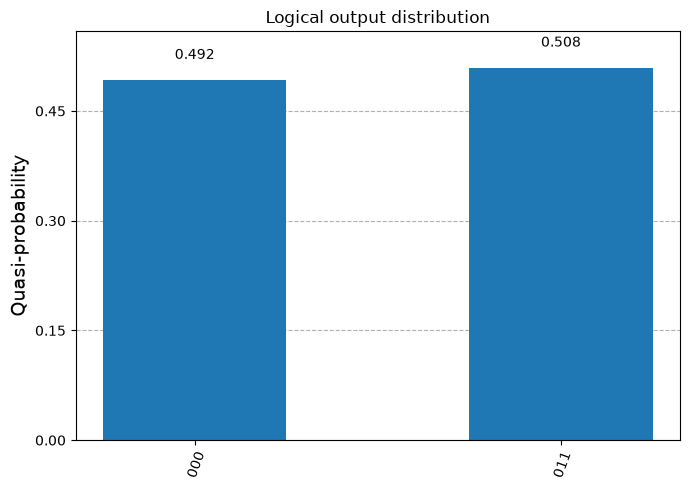

In [3]:
logical_counts = sample(source, shots=shots, seed=seed)
assert set(logical_counts) == {"000", "011"}
assert sum(logical_counts.values()) == shots
assert abs(logical_counts["000"] / shots - 0.5) < 0.05
plot_distribution(logical_counts, title="Logical output distribution")

## Describe two targets

A `CompilerTarget` is an immutable description used during compilation. It
specifies sites, connectivity, and supported operations. It does not open a
connection or execute a program.

Both models have three sites and the same native gates: RZ and RY rotations plus
controlled-X. Measurement is also supported. H is **not** native, so it must be
synthesized from rotations.

In [4]:
native_operations = CompilerTarget.NativeOperations([
    CompilerTarget.OperationCapability("rz", arity=1, num_parameters=1),
    CompilerTarget.OperationCapability("ry", arity=1, num_parameters=1),
    CompilerTarget.OperationCapability("cx", arity=2, num_parameters=0),
    CompilerTarget.OperationCapability("measure", arity=1, num_parameters=0),
])
line_edges = [(0, 1), (1, 2)]
targets = {
    "All-to-all": CompilerTarget(
        3,
        connectivity=CompilerTarget.Connectivity.all_to_all(),
        native_operations=native_operations,
    ),
    "Line": CompilerTarget(
        3,
        connectivity=CompilerTarget.Connectivity(line_edges),
        native_operations=native_operations,
    ),
}

`arity` is the number of qubits an operation acts on; `num_parameters` is its
number of gate parameters. An omitted placement list makes an operation
available on every placement permitted by the target topology. Our CX gates have
no additional direction restriction.

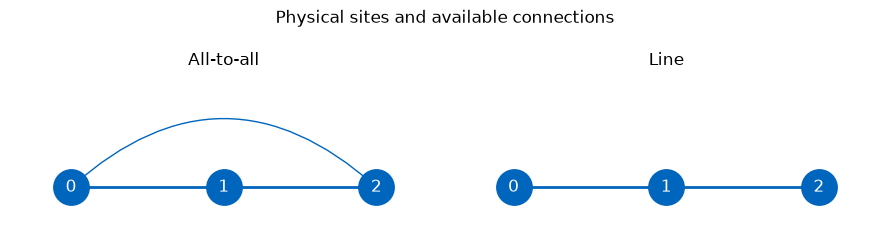

In [5]:
positions = [(0, 0), (1, 0), (2, 0)]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.4))
for ax, (name, edges) in zip(axes, [("All-to-all", [(0, 1), (1, 2), (0, 2)]), ("Line", line_edges)], strict=True):
    for left, right in edges:
        if (left, right) == (0, 2):
            ax.annotate(
                "",
                xy=positions[right],
                xytext=positions[left],
                arrowprops={
                    "arrowstyle": "-",
                    "connectionstyle": "arc3,rad=-0.45",
                    "color": "#0065bd",
                },
            )
        else:
            ax.plot([left, right], [0, 0], color="#0065bd", linewidth=2)
    ax.scatter([0, 1, 2], [0, 0, 0], s=650, color="#0065bd", zorder=3)
    for site, (x, y) in enumerate(positions):
        ax.text(x, y, str(site), ha="center", va="center", color="white", fontsize=12)
    ax.set(title=name, xlim=(-0.4, 2.4), ylim=(-0.3, 0.8))
    ax.axis("off")
fig.suptitle("Physical sites and available connections")
fig.tight_layout()

These models omit noise and calibration. Their purpose is to isolate the effect
of connectivity while keeping the native gate set fixed.

## Compile, then inspect the native circuits

**Placement** assigns program qubits to physical sites. **Routing** moves
quantum states when an interaction requires different neighbors.
**Native synthesis** expresses operations using the target's supported gates.
Routing can therefore increase the number of native gates even when
target-independent optimization has removed redundant work.

Predict which target needs more controlled-X gates, then compile:

All-to-all


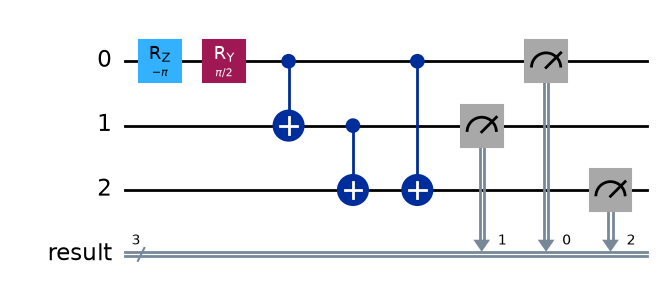

Line


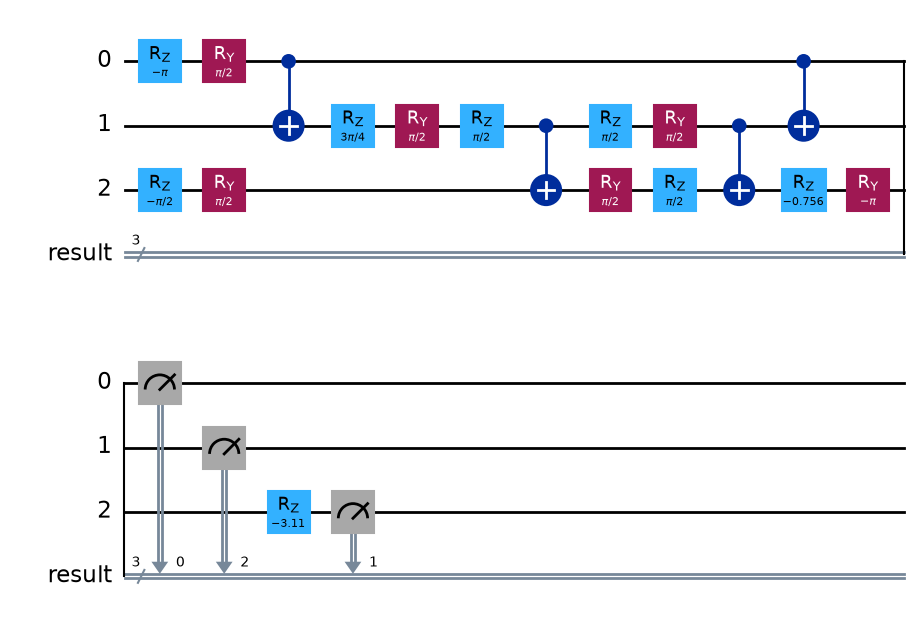

In [6]:
mapped = {
    name: compile_program(source, target=target, output=OutputFormat.OPENQASM3) for name, target in targets.items()
}
circuits = {name: QCProgram.from_openqasm_str(program.source).to_qiskit() for name, program in mapped.items()}
for name, circuit in circuits.items():
    print(name)
    display(circuit.draw("mpl", fold=12))

The figures use the emitted physical site order. A routing exchange may already
be decomposed into native gates, so do not expect an explicit SWAP symbol.
Measurements still write to the declared `result` register, even when their
source physical qubits have moved.

Compare the gate counts of these straight-line outputs:

In [7]:
print("Target       RZ   RY   CX")
for name, circuit in circuits.items():
    counts = circuit.count_ops()
    print(f"{name:11} {counts.get('rz', 0):3}  {counts.get('ry', 0):3}  {counts.get('cx', 0):3}")
assert circuits["Line"].count_ops()["cx"] > circuits["All-to-all"].count_ops()["cx"]

Target       RZ   RY   CX
All-to-all    1    1    3
Line          8    6    4


This experiment illustrates routing cost, not an optimality guarantee. The
compiler uses heuristics; exact layouts and decompositions can change between
versions or machines. By default, mapping uses at least eight initial-layout
trials, increasing the count to the number of available logical CPUs when that
is larger. The [target guide](https://mqt.readthedocs.io/projects/core/en/stable/mlir/target_compilation.html#define-a-target)
describes explicit pass options for reproducible mapping experiments.

Verify that the compiler used native gates and that every emitted CX on the line
joins adjacent sites:

In [8]:
for name, circuit in circuits.items():
    assert [(register.name, len(register)) for register in circuit.cregs] == [("result", 3)]
    assert set(circuit.count_ops()) <= {"rz", "ry", "cx", "measure", "store"}
    for instruction in circuit.data:
        if instruction.operation.name == "cx":
            sites = [circuit.find_bit(qubit).index for qubit in instruction.qubits]
            assert targets[name].supports_operation("cx", 2, 0, sites)
            if name == "Line":
                assert tuple(sorted(sites)) in line_edges
print("Native gates and CX connectivity checks passed.")

Native gates and CX connectivity checks passed.


The explicit topology check matters: an operation capability with no placement
list does not itself encode the coupling graph. The target compiler checks both
requirements.

## Preserve logical output bits after routing

Expand the emitted OpenQASM and inspect its final measurement assignments:

In [9]:
for name, program in mapped.items():
    print(name)
    display(Code(program.source, language="openqasm3"))

All-to-all


OPENQASM 3;
include "stdgates.inc";

bit[3] result;

rz(-3.1415926535897931) $0;
ry(1.5707963267948966) $0;
cx $0, $1;
cx $1, $2;
cx $0, $2;
result[0] = measure $0;
result[1] = measure $1;
result[2] = measure $2;

Line


OPENQASM 3;
include "stdgates.inc";

bit[3] result;

rz(-3.1415926535897931) $0;
ry(1.5707963267948966) $0;
cx $0, $1;
rz(-1.5707963267948966) $2;
ry(1.5707963267948966) $2;
rz(2.3561944901923448) $1;
ry(1.5707963267948966) $1;
rz(1.5707963267948966) $1;
cx $1, $2;
ry(1.5707963267948966) $2;
rz(1.5707963267948966) $2;
rz(1.5707963267948966) $1;
ry(1.5707963267948966) $1;
cx $1, $2;
rz(-0.75596941042390764) $2;
ry(-3.1415926535897931) $2;
rz(-3.1121639006162525) $2;
cx $0, $1;
result[1] = measure $2;
result[0] = measure $0;
result[2] = measure $1;

`$0`, `$1`, and `$2` identify physical sites. The assignments to `result` retain
the logical output order. In particular, the rightmost character in a count
string is `result[0]`, not necessarily the measurement of physical site 0.

The H gate has become rotations. Neither target lists `gphase` as native, so
target synthesis may remove the entry point's unobservable global phase while
preserving relative phase effects. Unlike the target-independent cancellation
experiment, comparing raw unitary matrices without accounting for global phase
and physical permutations would not be an appropriate check here.

Sample the emitted programs through the local QCO interpreter:

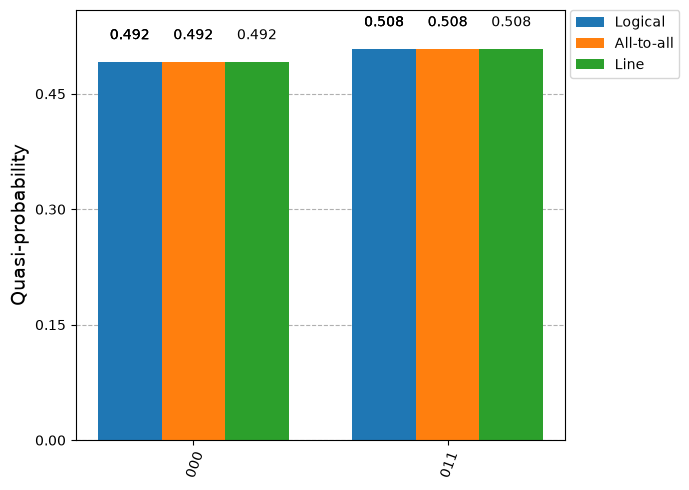

In [10]:
mapped_counts = {name: sample(program, shots=shots, seed=seed) for name, program in mapped.items()}
for counts in mapped_counts.values():
    assert set(counts) == {"000", "011"}
    assert sum(counts.values()) == shots
    assert abs(counts["000"] / shots - 0.5) < 0.05
plot_distribution([logical_counts, *mapped_counts.values()], legend=["Logical", *mapped_counts])

Both targets retain the expected **logical measurement distribution**. This is
an observable check for this input, not a proof of equivalence on every input
state. Even with the same seed, transformed programs need not produce identical
finite-shot histograms.

## Checkpoint: return to the slides

Explain why the line needs more native gates and why its logical outputs still
agree with the all-to-all target. The core compilation exercise is complete.
Return to the slides for QDMI and HPC integration. Everything below is optional.

## Experiment: remove the routing constraint

Replace the line with a triangle, connecting every pair of sites. Predict
whether any extra routing gates will be needed:

In [11]:
triangle = CompilerTarget(
    3,
    connectivity=CompilerTarget.Connectivity([*line_edges, (0, 2)]),
    native_operations=native_operations,
)
triangle_program = compile_program(source, target=triangle, output=OutputFormat.OPENQASM3)
triangle_circuit = QCProgram.from_openqasm_str(triangle_program.source).to_qiskit()
triangle_counts = sample(triangle_program, shots=shots, seed=seed)
assert set(triangle_counts) == {"000", "011"}
assert sum(triangle_counts.values()) == shots
assert abs(triangle_counts["000"] / shots - 0.5) < 0.05
assert triangle_circuit.count_ops()["cx"] < circuits["Line"].count_ops()["cx"]
print(triangle_circuit.count_ops())

OrderedDict({'cx': 3, 'measure': 3, 'rz': 1, 'ry': 1})


<details>
<summary>Explain the result</summary>

The triangle allows all three logical interactions without routing exchanges.
Native synthesis is still required because H is not native. Connectivity and the
native gate set impose separate requirements.

</details>

## Experiment: provide too few sites

This program needs three qubits at once, so a two-site target is too small. The
following example catches the compilation error and prints its diagnostic:

In [12]:
too_small = CompilerTarget(
    2,
    connectivity=CompilerTarget.Connectivity.all_to_all(),
    native_operations=native_operations,
)
try:
    compile_program(source, target=too_small, output=OutputFormat.OPENQASM3)
except RuntimeError as error:
    print(f"Expected compilation failure: {error}")
else:
    raise AssertionError("The three-qubit program must not fit on this two-site target")

Expected compilation failure: loc("<qc-program-builder>":1:1): requires 3 program qubits, but the target site count is 2
note: loc("<qc-program-builder>":1:1): see current operation: 
"func.func"() <{function_type = () -> !cbit.reg<3>, sym_name = "main"}> ({
  %0 = "arith.constant"() <{value = 2 : index}> : () -> index
  %1 = "arith.constant"() <{value = 1 : index}> : () -> index
  %2 = "arith.constant"() <{value = 0 : index}> : () -> index
  %3 = "arith.constant"() <{value = 3 : index}> : () -> index
  %4 = "qtensor.alloc"(%3) {mqt.register_name = "q"} : (index) -> tensor<3x!qco.qubit>
  %5 = "cbit.alloc"() <{initialization = #cbit.init<undefined>}> {mqt.register_name = "result"} : () -> !cbit.reg<3>
  %6:2 = "qtensor.extract"(%4, %2) : (tensor<3x!qco.qubit>, index) -> (tensor<3x!qco.qubit>, !qco.qubit)
  %7 = "qco.h"(%6#1) : (!qco.qubit) -> !qco.qubit
  %8:2 = "qtensor.extract"(%6#0, %1) : (tensor<3x!qco.qubit>, index) -> (tensor<3x!qco.qubit>, !qco.qubit)
  %9:2 = "qco.ctrl"(%7, %8#

The diagnostic reports the required program qubits and available target sites.
It does not indicate a Python syntax error or a missing installation. Qubit
reuse is a separate optimization with its own applicability conditions; merely
declaring a smaller target does not make it possible.

## Connect compilation and execution with QDMI

The **Quantum Device Management Interface (QDMI)** defines a common C interface
for querying device capabilities, submitting jobs, checking their status, and
retrieving results. MQT Core's driver loads device implementations and exposes
them through Python and C++.

QDMI can connect to a local simulator, a QPU, or a cloud service. The device
reports which program formats it accepts; QDMI does not require every device to
use the same format. `compile_program` uses those capabilities to prepare a
program, and `submit_program` creates a job for it. The
[QDMI overview](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/index.html) explains the layers and links to Amazon
Braket and IQM integration case studies.

### Compile for an execution device

A target model describes constraints. A **QDMI device** also accepts jobs. Open
the packaged DDSIM device and compile the logical source for its actual
capabilities:

In [13]:
device = open_device("mqt.ddsim.default")
compiled = compile_program(source, target=device)
print(f"Selected program format: {compiled.program_format.name}")
print(f"Payload type: {type(compiled.payload).__name__}")

Selected program format: QASM3
Payload type: str


The printed format shows which representation the compiler selected for DDSIM.
The `CompiledProgram` holds the serialized program together with the device
properties and format restrictions used to compile it. DDSIM also supports
structured programs such as the previous notebook's feedback example.

Submission is a separate operation that explicitly names the destination:

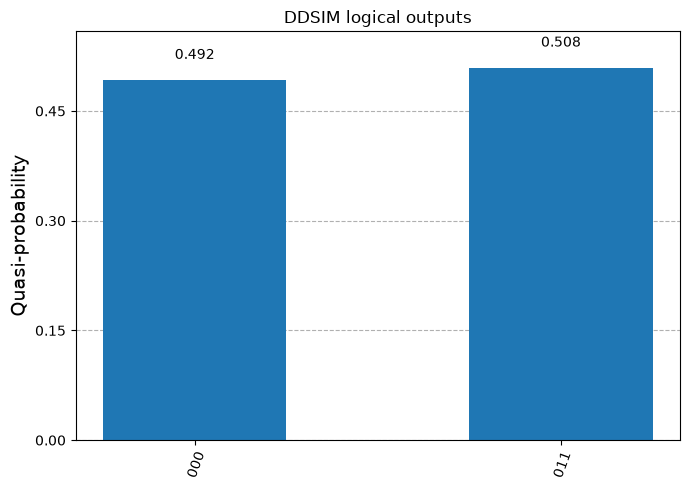

In [14]:
job = submit_program(compiled, target=device, num_shots=shots, custom1=seed)
job.wait()
device_counts = job.get_counts()
assert set(device_counts) == {"000", "011"}
assert sum(device_counts.values()) == shots
assert abs(device_counts["000"] / shots - 0.5) < 0.05
plot_distribution(device_counts, title="DDSIM logical outputs")

`job.wait()` waits for completion and reports execution failure. `custom1`
selects DDSIM's random seed; custom job parameters are device-specific.

A `CompiledProgram` is tied to the target and execution-format requirements used
during compilation. Submission checks that the destination meets those
requirements. Do not compile a hardware-model artifact and assume that
substituting DDSIM as its destination will work. Here we simulated the models'
OpenQASM for comparison, then compiled the logical source for DDSIM before
submitting it. A compiled DDSIM program can be submitted again without
recompilation while the device continues to meet its requirements.

## Continue to execution and exchange

Continue with [Execute programs with QIR](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/qir_execution.html) to inspect the executable program, then
[Run programs through QDMI](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/qdmi_execution.html) to explore the device and job API. The
[Exchange structured programs with jeff](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/jeff_exchange.html) tutorial shows how to hand programs to another compiler
before choosing an execution format.

For further reference:

- Use [target compilation guide](https://mqt.readthedocs.io/projects/core/en/stable/mlir/target_compilation.html) for device discovery, execution-format
  selection, target capabilities, and control-flow restrictions.
- Read [Compiler Collection](https://mqt.readthedocs.io/projects/core/en/stable/mlir/mqt_compiler_collection.html) for compiler checkpoints, pass
  pipelines, serialization, and the Python, CLI, and C++ interfaces.
- Explore [Qiskit compatibility](https://mqt.readthedocs.io/projects/core/en/stable/mlir/qiskit.html), [OpenQASM](https://mqt.readthedocs.io/projects/core/en/stable/mlir/OpenQASM.html), and
  [QIR](https://mqt.readthedocs.io/projects/core/en/stable/qir/index.html) for interoperability and output formats.
- Try [benchmarks](https://mqt.readthedocs.io/projects/core/en/stable/benchmarks.html) for structured programs with references.
- Use [MLIR development policy](https://mqt.readthedocs.io/projects/core/en/stable/development.html#mlir) when you are ready to
  implement a compiler change.